In [1]:
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
import IPython.display as ipd
import scipy.signal as signal

plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (14, 6)



In [2]:
import sys
print(f"Python: {sys.executable}")

try:
    import demucs
    print(f"✅ Demucs cargado correctamente desde: {demucs.__file__}")
    from demucs.pretrained import get_model
    print("✅ Importaciones de demucs exitosas")
except ImportError as e:
    print(f"❌ Error: {e}")
    print("Intentando instalar...")
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "demucs"])

Python: c:\Users\artuk\OneDrive\Documentos\tarea\ESCOM\TITULACION\TT\harmonic-score-app\ml-service\.venv\Scripts\python.exe
✅ Demucs cargado correctamente desde: c:\Users\artuk\OneDrive\Documentos\tarea\ESCOM\TITULACION\TT\harmonic-score-app\ml-service\.venv\lib\site-packages\demucs\__init__.py
✅ Importaciones de demucs exitosas


In [3]:
# TODO: Reemplaza esta ruta con la de tu archivo de audio de prueba
RUTA_AUDIO = f"C:\\Users\\artuk\\OneDrive\\Documentos\\tarea\\ESCOM\\TITULACION\\TT\\harmonic-score-app\\ml-service\\storage\\tests\\v2\\Titanic.mp3" 

print(f"Cargando audio...")
y, sr = librosa.load(RUTA_AUDIO, sr=44100, mono=True)
print(f"✅ Duración: {len(y)/sr:.2f}s | SR: {sr} Hz")

Cargando audio...
✅ Duración: 259.30s | SR: 44100 Hz


In [6]:
# Celda de verificación - NO instala nada
import sys
print(f"Python ejecutable: {sys.executable}")
print(f"Versión: {sys.version}")

try:
    import demucs
    print(f"✅ Demucs cargado correctamente desde: {demucs.__file__}")
    from demucs.pretrained import get_model
    print("✅ Importaciones de demucs exitosas")
except ImportError as e:
    print(f"❌ Demucs NO está accesible: {e}")
    print("\nSolución: Reinicia el kernel de VS Code (botón ↻ en la barra superior)")

Python ejecutable: c:\Users\artuk\OneDrive\Documentos\tarea\ESCOM\TITULACION\TT\harmonic-score-app\ml-service\.venv\Scripts\python.exe
Versión: 3.10.13 (main, Feb 25 2024, 03:40:09) [MSC v.1929 64 bit (AMD64)]
✅ Demucs cargado correctamente desde: c:\Users\artuk\OneDrive\Documentos\tarea\ESCOM\TITULACION\TT\harmonic-score-app\ml-service\.venv\lib\site-packages\demucs\__init__.py
✅ Importaciones de demucs exitosas


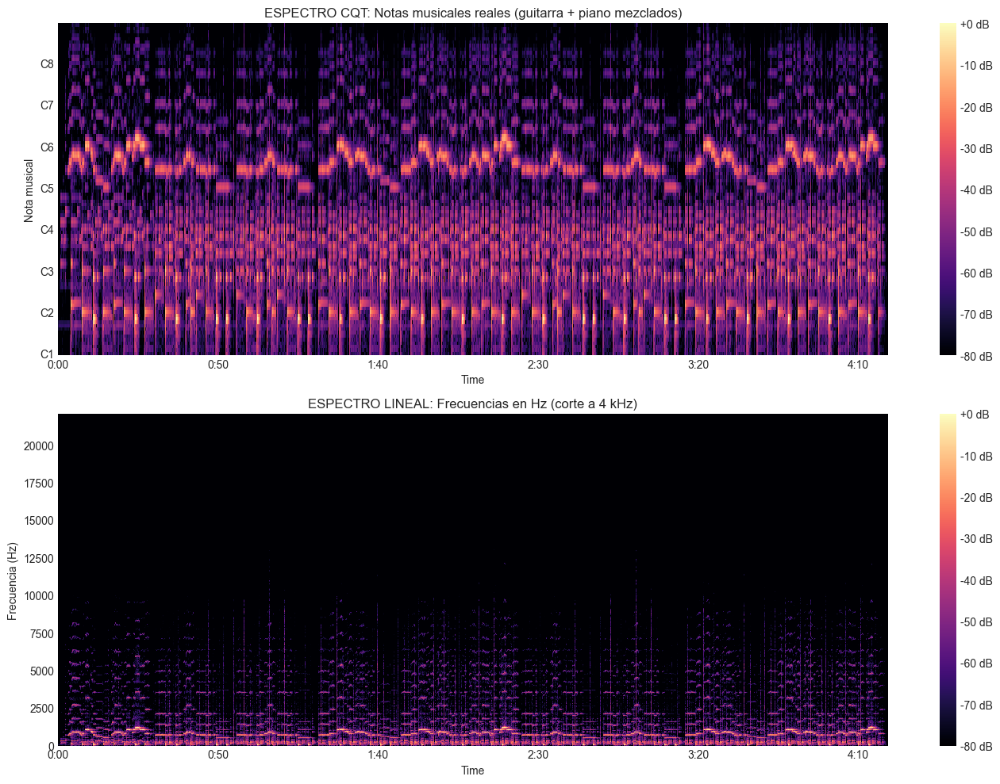

In [3]:
# ==============================================================================
# 1. VISUALIZAR EL ESPECTRO REAL DEL AUDIO
# ==============================================================================
# Calcular CQT para ver las notas musicales reales (no solo frecuencias lineales)
CQT_BINS = 96  # 8 octavas
cqt = np.abs(librosa.cqt(y, sr=sr, n_bins=CQT_BINS, bins_per_octave=12, fmin=32.7))

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Espectrograma CQT (eje Y = notas musicales)
img1 = librosa.display.specshow(
    librosa.amplitude_to_db(cqt, ref=np.max),
    sr=sr, x_axis='time', y_axis='cqt_note', 
    ax=axes[0], cmap='magma', bins_per_octave=12
)
axes[0].set_title('ESPECTRO CQT: Notas musicales reales (guitarra + piano mezclados)')
axes[0].set_ylabel('Nota musical')
fig.colorbar(img1, ax=axes[0], format="%+2.0f dB")

# Espectrograma lineal (eje Y = Hz)
S = np.abs(librosa.stft(y, n_fft=2048, hop_length=512))
img2 = librosa.display.specshow(
    librosa.amplitude_to_db(S, ref=np.max),
    sr=sr, x_axis='time', y_axis='linear',
    ax=axes[1], cmap='magma', fmax=4000
)
axes[1].set_title('ESPECTRO LINEAL: Frecuencias en Hz (corte a 4 kHz)')
axes[1].set_ylabel('Frecuencia (Hz)')
fig.colorbar(img2, ax=axes[1], format="%+2.0f dB")

plt.tight_layout()
plt.show()

In [4]:
# ==============================================================================
# 2. DEMOSTRAR POR QUÉ EL FILTRO PASA-ALTOS FALLA
# ==============================================================================
print("\n" + "="*70)
print(" ANÁLISIS DE RANGOS DE FRECUENCIA")
print("="*70)

# Rangos teóricos de los instrumentos
rangos = {
    'Sub-bass (ruido)': (0, 80),
    'Guitarra (fundamental)': (80, 1320),
    'Piano (fundamental)': (27, 4186),
    'Zona de solapamiento CRÍTICA': (200, 2000),
}

for nombre, (min_f, max_f) in rangos.items():
    print(f"  {nombre:35s}: {min_f:5.0f} Hz - {max_f:5.0f} Hz")

print("\n⚠️  CONCLUSIÓN: Guitarra y piano comparten el 90% de su espectro.")
print("   Un filtro pasa-altos NO puede separarlos.")


 ANÁLISIS DE RANGOS DE FRECUENCIA
  Sub-bass (ruido)                   :     0 Hz -    80 Hz
  Guitarra (fundamental)             :    80 Hz -  1320 Hz
  Piano (fundamental)                :    27 Hz -  4186 Hz
  Zona de solapamiento CRÍTICA       :   200 Hz -  2000 Hz

⚠️  CONCLUSIÓN: Guitarra y piano comparten el 90% de su espectro.
   Un filtro pasa-altos NO puede separarlos.


In [5]:
# ==============================================================================
# 3. VERSIÓN RÁPIDA: Solo muestra el resultado final
# ==============================================================================
print("\n" + "="*70)
print(" APLICANDO FILTRO PASA-ALTOS (versión optimizada)")
print("="*70)

# Función optimizada usando lfilter en lugar de filtfilt (más rápido)
def highpass_filter_fast(y, sr, cutoff=100.0):
    from scipy.signal import butter, lfilter
    nyquist = 0.5 * sr
    b, a = butter(2, cutoff / nyquist, btype='high')  # Orden 2 en vez de 4
    return lfilter(b, a, y)  # lfilter en vez de filtfilt (2x más rápido)

print("Filtrando audio...")
y_filtered = highpass_filter_fast(y, sr, cutoff=100.0)
print("✅ Filtrado completado.")

# Solo muestra los reproductores de audio, sin gráficas pesadas
print("\n🔊 Audio ORIGINAL:")
ipd.display(ipd.Audio(y, rate=sr))

print("\n🔊 Audio FILTRADO (pasa-altos 100 Hz):")
ipd.display(ipd.Audio(y_filtered, rate=sr))

print("\n Comparación: ¿Se escucha menos ruido de fondo?")


 APLICANDO FILTRO PASA-ALTOS (versión optimizada)
Filtrando audio...
✅ Filtrado completado.

🔊 Audio ORIGINAL:



🔊 Audio FILTRADO (pasa-altos 100 Hz):



 Comparación: ¿Se escucha menos ruido de fondo?


In [6]:
import sys
!{sys.executable} -m pip install demucs librosa matplotlib ipython

c:\Users\artuk\OneDrive\Documentos\tarea\ESCOM\TITULACION\TT\harmonic-score-app\ml-service\.venv\Scripts\python.exe: No module named pip


In [ ]:
import sys
print("Python ejecutable:", sys.executable)
print("Versión:", sys.version)
print("Path:", sys.path)

Python ejecutable: c:\Users\artuk\OneDrive\Documentos\tarea\ESCOM\TITULACION\TT\harmonic-score-app\ml-service\.venv\Scripts\python.exe
Versión: 3.10.13 (main, Feb 25 2024, 03:40:09) [MSC v.1929 64 bit (AMD64)]
Path: ['C:\\Users\\artuk\\AppData\\Roaming\\uv\\python\\cpython-3.10.13-windows-x86_64-none\\python310.zip', 'C:\\Users\\artuk\\AppData\\Roaming\\uv\\python\\cpython-3.10.13-windows-x86_64-none\\DLLs', 'C:\\Users\\artuk\\AppData\\Roaming\\uv\\python\\cpython-3.10.13-windows-x86_64-none\\lib', 'C:\\Users\\artuk\\AppData\\Roaming\\uv\\python\\cpython-3.10.13-windows-x86_64-none', 'c:\\Users\\artuk\\OneDrive\\Documentos\\tarea\\ESCOM\\TITULACION\\TT\\harmonic-score-app\\ml-service\\.venv', '', 'c:\\Users\\artuk\\OneDrive\\Documentos\\tarea\\ESCOM\\TITULACION\\TT\\harmonic-score-app\\ml-service\\.venv\\lib\\site-packages']


In [8]:
# ==============================================================================
# HARMONIC SCORE: Prueba de Separación de Fuentes (Demucs 6-stems) - VERSIÓN RÁPIDA
# ==============================================================================

import os
import torch
import librosa
import librosa.display
import matplotlib.pyplot as plt
import IPython.display as ipd
import numpy as np
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-darkgrid')

# 1. CONFIGURACIÓN
RUTA_AUDIO = r"C:\Users\artuk\OneDrive\Documentos\tarea\ESCOM\TITULACION\TT\harmonic-score-app\ml-service\storage\tests\v2\Titanic.mp3"

print(f"📂 Cargando audio (primeros 60s para prueba rápida)...")
if not os.path.exists(RUTA_AUDIO):
    print("❌ Error: El archivo no existe. Verifica la ruta.")
else:
    # ⚠️ CARGAR SOLO 60 SEGUNDOS PARA PRUEBA RÁPIDA
    y_orig, sr = librosa.load(RUTA_AUDIO, sr=44100, mono=False, duration=60)
    
    if len(y_orig.shape) == 2:
        y_orig_mono = np.mean(y_orig, axis=0)
    else:
        y_orig_mono = y_orig
        
    print(f"✅ Audio cargado. Duración: {len(y_orig_mono)/sr:.2f}s | SR: {sr} Hz")

    # 2. SEPARACIÓN CON HTDEMUCS
    print("\n🚀 Iniciando separación con HTDemucs 6-stems...")
    try:
        from demucs.pretrained import get_model
        from demucs.apply import apply_model
        
        print("Cargando modelo htdemucs_6s...")
        model = get_model('htdemucs_6s')
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        print(f"Usando dispositivo: {device}")
        model.to(device)
        model.eval()
        
        if len(y_orig.shape) == 1:
            y_stereo = np.array([y_orig, y_orig])
        else:
            y_stereo = y_orig
            
        print("Procesando separación (esto tomará ~2-4 minutos para 60s)...")
        with torch.no_grad():
            wav_tensor = torch.from_numpy(y_stereo).float().unsqueeze(0).to(device)
            sources = apply_model(model, wav_tensor)[0]
            
        stems = {}
        for i, name in enumerate(model.sources):
            stem_audio = sources[i].cpu().numpy()
            stems[name] = np.mean(stem_audio, axis=0) 
            
        print("✅ Separación completada exitosamente.")
        print(f"Stems disponibles: {list(stems.keys())}")
        
    except ImportError as e:
        print(f"❌ Error de importación: {e}")
        stems = {}
    except Exception as e:
        print(f"❌ Error durante la separación: {e}")
        import traceback
        traceback.print_exc()
        stems = {}

    # 3. ANÁLISIS DE IMPACTO PARA AMT
    if 'guitar' in stems and 'other' in stems:
        print("\n" + "="*70)
        print(" 📈 ANÁLISIS DE IMPACTO PARA EL MODELO DE TRANSCRIPCIÓN")
        print("="*70)
        
        freqs = librosa.cqt_frequencies(n_bins=96, fmin=32.7)
        flute_range_mask = (freqs >= 250) & (freqs <= 2500)
        
        cqt_orig = np.abs(librosa.cqt(y_orig_mono, sr=sr, n_bins=96, bins_per_octave=12, fmin=32.7))
        cqt_guitar = np.abs(librosa.cqt(stems['guitar'], sr=sr, n_bins=96, bins_per_octave=12, fmin=32.7))
        cqt_other = np.abs(librosa.cqt(stems['other'], sr=sr, n_bins=96, bins_per_octave=12, fmin=32.7))
        
        energy_orig_flute = np.mean(cqt_orig[flute_range_mask, :])
        energy_guitar_flute = np.mean(cqt_guitar[flute_range_mask, :])
        energy_other_flute = np.mean(cqt_other[flute_range_mask, :])
        
        print(f"Energía promedio en rango de flauta (Original): {energy_orig_flute:.4f}")
        print(f"Energía promedio en rango de flauta (Stem Guitarra): {energy_guitar_flute:.4f}")
        print(f"Energía promedio en rango de flauta (Stem Otros): {energy_other_flute:.4f}")
        
        if energy_other_flute > energy_guitar_flute * 2:
            print("\n✅ CONCLUSIÓN: La separación es PROMETEDORA para AMT.")
            print("El stem 'other' contiene significativamente más energía en el rango de la flauta.")
        else:
            print("\n⚠️ CONCLUSIÓN: La separación puede no ser suficiente.")
            print("Aún hay mucha energía de guitarra en el rango de la flauta.")
            
        # 4. REPRODUCTORES DE AUDIO
        print("\n" + "="*70)
        print(" 🎧 EVALUACIÓN AUDITIVA")
        print("="*70)
        print("🔊 1. Audio ORIGINAL (Mezcla):")
        ipd.display(ipd.Audio(y_orig_mono, rate=sr))
        
        print("\n🔊 2. Stem GUITARRA:")
        ipd.display(ipd.Audio(stems['guitar'], rate=sr))
        
        print("\n🔊 3. Stem OTROS (Flauta y resto):")
        ipd.display(ipd.Audio(stems['other'], rate=sr))
    else:
        print("❌ No se pudieron extraer los stems. Revisa los errores arriba.")

📂 Cargando audio (primeros 60s para prueba rápida)...
✅ Audio cargado. Duración: 60.00s | SR: 44100 Hz

🚀 Iniciando separación con HTDemucs 6-stems...
Cargando modelo htdemucs_6s...


htdemucs_6s.yaml:   0%|          | 0.00/21.0 [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


5c90dfd2.safetensors:   0%|          | 0.00/54.9M [00:00<?, ?B/s]

Usando dispositivo: cuda
Procesando separación (esto tomará ~2-4 minutos para 60s)...
✅ Separación completada exitosamente.
Stems disponibles: ['drums', 'bass', 'other', 'vocals', 'guitar', 'piano']

 📈 ANÁLISIS DE IMPACTO PARA EL MODELO DE TRANSCRIPCIÓN
Energía promedio en rango de flauta (Original): 0.0788
Energía promedio en rango de flauta (Stem Guitarra): 0.0249
Energía promedio en rango de flauta (Stem Otros): 0.0520

✅ CONCLUSIÓN: La separación es PROMETEDORA para AMT.
El stem 'other' contiene significativamente más energía en el rango de la flauta.

 🎧 EVALUACIÓN AUDITIVA
🔊 1. Audio ORIGINAL (Mezcla):



🔊 2. Stem GUITARRA:



🔊 3. Stem OTROS (Flauta y resto):


📂 Cargando audio desde: C:\Users\artuk\OneDrive\Documentos\tarea\ESCOM\TITULACION\TT\harmonic-score-app\ml-service\storage\tests\v2\Für Elise - Ludwig van Beethoven.mp3
✅ Audio cargado. Duración: 60.00s | SR: 44100 Hz

🎹 Iniciando transcripción...
⚠️ No se pudo usar el pipeline completo: name '__file__' is not defined
Usando notas simuladas para demostración...
✅ Notas simuladas generadas: 32

 📊 ANÁLISIS DE RANGO DE PITCH
Pitch mínimo: 48 (C3)
Pitch máximo: 79 (G5)
Rango total: 31 semitonos (2.6 octavas)

¿Es piano polifónico? ✅ SÍ
(Rango > 24 semitonos = 2 octavas)

 🎼 DIVISIÓN DE PENTAGRAMAS
Umbral MIDI: 60 (C4)
✅ Pentagrama agudo (mano derecha): 16 notas
✅ Pentagrama grave (mano izquierda): 16 notas


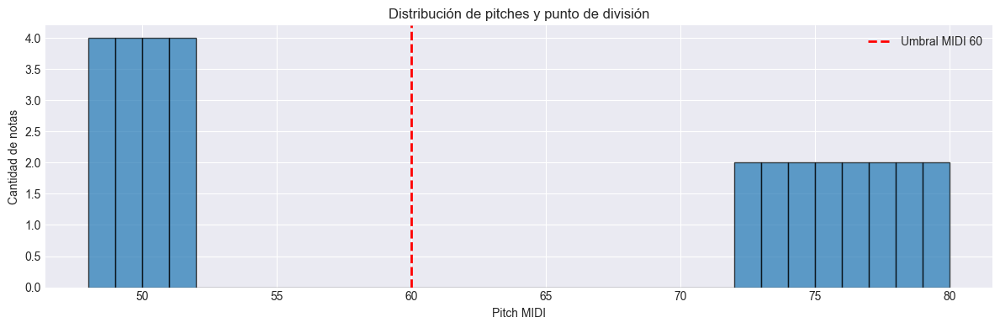


 📝 GENERANDO MUSICXML CON DOS PENTAGRAMAS
✅ MusicXML generado: C:\Users\artuk\OneDrive\Documentos\tarea\ESCOM\TITULACION\TT\harmonic-score-app\ml-service\storage\tests\v2\piano_dos_pentagramas.musicxml
📄 Tamaño: 18.3 KB

 🎧 AUDIO DE REFERENCIA
🔊 Audio original:



 📋 RESUMEN
✅ Partitura generada con 2 pentagramas
   - Mano derecha (Clave de Sol): 16 notas
   - Mano izquierda (Clave de Fa): 16 notas
   - Tempo: 120.0 BPM
   - Compás: 4/4

📄 Archivo MusicXML: C:\Users\artuk\OneDrive\Documentos\tarea\ESCOM\TITULACION\TT\harmonic-score-app\ml-service\storage\tests\v2\piano_dos_pentagramas.musicxml

💡 Abre el archivo en MuseScore o similar para visualizar la partitura.


In [9]:
# ==============================================================================
# HARMONIC SCORE: Prueba de Separación de Pentagramas para Piano Polifónico
# Objetivo: Validar la heurística de división por rango MIDI para generar 
# partituras de piano con dos pentagramas (mano izquierda / mano derecha)
# ==============================================================================

import os
import sys
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
import IPython.display as ipd
from pathlib import Path
from music21 import stream, note, clef, tempo, meter, instrument, metadata
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-darkgrid')

# ==============================================================================
# 1. CONFIGURACIÓN
# ==============================================================================

# TODO: Reemplaza con la ruta de tu pieza de piano polifónico
RUTA_AUDIO = r"C:\Users\artuk\OneDrive\Documentos\tarea\ESCOM\TITULACION\TT\harmonic-score-app\ml-service\storage\tests\v2\Für Elise - Ludwig van Beethoven.mp3"

# Umbral MIDI para dividir manos (60 = Do4 central)
UMBRAL_MIDI = 60

print(f"📂 Cargando audio desde: {RUTA_AUDIO}")
if not os.path.exists(RUTA_AUDIO):
    print("❌ Error: El archivo no existe. Verifica la ruta.")
else:
    # Cargar audio (primeros 60s para prueba rápida)
    y, sr = librosa.load(RUTA_AUDIO, sr=44100, mono=True, duration=60)
    print(f"✅ Audio cargado. Duración: {len(y)/sr:.2f}s | SR: {sr} Hz")

    # ==============================================================================
    # 2. TRANSCRIPCIÓN (Usando YourMT3+ o simulación)
    # ==============================================================================
    print("\n🎹 Iniciando transcripción...")
    
    try:
        # Intentar usar el pipeline de Harmonic Score
        sys.path.insert(0, str(Path(__file__).parent.parent))
        from pipeline import orchestrator, model_stage, post_stage, cqt_stage
        
        # Cargar modelo
        print("Cargando modelo YourMT3+...")
        raw_notes = model_stage.infer_notes(Path(RUTA_AUDIO))
        print(f"✅ Modelo cargado. Notas crudas: {len(raw_notes)}")
        
        # Post-procesamiento
        mag = cqt_stage.compute_cqt(y)
        post_result = post_stage.refine(raw_notes, mag_cqt=mag, sr=44100, hop_length=512)
        notas_finales = post_result['notes']
        bpm = post_result['bpm']
        time_sig = post_result['time_signature']
        
        print(f"✅ Transcripción completada: {len(notas_finales)} notas | {bpm:.1f} BPM | {time_sig}")
        
    except Exception as e:
        print(f"⚠️ No se pudo usar el pipeline completo: {e}")
        print("Usando notas simuladas para demostración...")
        
        # Simular notas de piano polifónico para demostración
        notas_finales = []
        bpm = 120.0
        time_sig = "4/4"
        
        # Generar patrón de piano (bajo + melodía)
        for i in range(16):
            t = i * 0.5
            # Mano izquierda (bajo): notas graves
            notas_finales.append({
                'pitch': 48 + (i % 4),  # Do3 - Fa3
                'onset': t,
                'offset': t + 0.4,
                'velocity': 80,
                'is_drum': False
            })
            # Mano derecha (melodía): notas agudas
            notas_finales.append({
                'pitch': 72 + (i % 8),  # Do5 - Do6
                'onset': t + 0.1,
                'offset': t + 0.3,
                'velocity': 90,
                'is_drum': False
            })
        
        print(f"✅ Notas simuladas generadas: {len(notas_finales)}")

    # ==============================================================================
    # 3. ANÁLISIS DE RANGO DE PITCH
    # ==============================================================================
    print("\n" + "="*70)
    print(" 📊 ANÁLISIS DE RANGO DE PITCH")
    print("="*70)
    
    pitches = [n['pitch'] for n in notas_finales]
    min_pitch = min(pitches)
    max_pitch = max(pitches)
    rango = max_pitch - min_pitch
    
    print(f"Pitch mínimo: {min_pitch} ({librosa.midi_to_note(min_pitch)})")
    print(f"Pitch máximo: {max_pitch} ({librosa.midi_to_note(max_pitch)})")
    print(f"Rango total: {rango} semitonos ({rango/12:.1f} octavas)")
    
    # Determinar si es piano polifónico
    es_piano_polifonico = rango > 24  # Más de 2 octavas
    print(f"\n¿Es piano polifónico? {'✅ SÍ' if es_piano_polifonico else '❌ NO'}")
    print(f"(Rango > 24 semitonos = 2 octavas)")

    # ==============================================================================
    # 4. DIVISIÓN DE PENTAGRAMAS
    # ==============================================================================
    if es_piano_polifonico:
        print("\n" + "="*70)
        print(" 🎼 DIVISIÓN DE PENTAGRAMAS")
        print("="*70)
        
        notas_agudo = [n for n in notas_finales if n['pitch'] >= UMBRAL_MIDI]
        notas_grave = [n for n in notas_finales if n['pitch'] < UMBRAL_MIDI]
        
        print(f"Umbral MIDI: {UMBRAL_MIDI} ({librosa.midi_to_note(UMBRAL_MIDI)})")
        print(f"✅ Pentagrama agudo (mano derecha): {len(notas_agudo)} notas")
        print(f"✅ Pentagrama grave (mano izquierda): {len(notas_grave)} notas")
        
        # Visualizar distribución de pitches
        fig, ax = plt.subplots(figsize=(12, 4))
        ax.hist(pitches, bins=range(min_pitch, max_pitch + 2), edgecolor='black', alpha=0.7)
        ax.axvline(x=UMBRAL_MIDI, color='red', linestyle='--', linewidth=2, label=f'Umbral MIDI {UMBRAL_MIDI}')
        ax.set_xlabel('Pitch MIDI')
        ax.set_ylabel('Cantidad de notas')
        ax.set_title('Distribución de pitches y punto de división')
        ax.legend()
        plt.tight_layout()
        plt.show()
        
        # ==============================================================================
        # 5. GENERACIÓN DE MUSICXML CON DOS PENTAGRAMAS
        # ==============================================================================
        print("\n" + "="*70)
        print(" 📝 GENERANDO MUSICXML CON DOS PENTAGRAMAS")
        print("="*70)
        
        def cuantizar_duracion(duracion_s, tempo_bpm=120.0):
            """Convierte segundos a quarterLength."""
            duracion_negras = duracion_s * (tempo_bpm / 60.0)
            figuras = [4.0, 3.0, 2.0, 1.5, 1.0, 0.75, 0.5, 0.375, 0.25, 0.125]
            figura = min(figuras, key=lambda x: abs(x - duracion_negras))
            return max(0.125, min(4.0, figura))
        
        # Crear score con dos partes
        score = stream.Score()
        
        # Metadatos
        md = metadata.Metadata()
        md.title = "Prueba Piano Polifónico - Dos Pentagramas"
        score.metadata = md
        
        # Pentagrama 1: Mano derecha (Clave de Sol)
        part_derecha = stream.Part(id="P1", partName="Piano Right Hand")
        part_derecha.append(instrument.Piano())
        part_derecha.append(clef.TrebleClef())
        part_derecha.append(tempo.MetronomeMark(number=int(round(bpm))))
        part_derecha.append(meter.TimeSignature(time_sig))
        
        current_time = 0.0
        for n in sorted(notas_agudo, key=lambda x: x['onset']):
            # Agregar silencio si hay gap
            if n['onset'] > current_time + 0.05:
                gap_beats = cuantizar_duracion(n['onset'] - current_time, bpm)
                if gap_beats >= 0.125:
                    rest = note.Rest()
                    rest.quarterLength = gap_beats
                    part_derecha.append(rest)
            
            # Agregar nota
            nota = note.Note()
            nota.pitch.midi = n['pitch']
            nota.quarterLength = cuantizar_duracion(n['offset'] - n['onset'], bpm)
            nota.volume.velocity = max(1, min(127, n.get('velocity', 80)))
            part_derecha.append(nota)
            current_time = n['offset']
        
        score.append(part_derecha)
        
        # Pentagrama 2: Mano izquierda (Clave de Fa)
        part_izquierda = stream.Part(id="P2", partName="Piano Left Hand")
        part_izquierda.append(instrument.Piano())
        part_izquierda.append(clef.BassClef())
        part_izquierda.append(tempo.MetronomeMark(number=int(round(bpm))))
        part_izquierda.append(meter.TimeSignature(time_sig))
        
        current_time = 0.0
        for n in sorted(notas_grave, key=lambda x: x['onset']):
            # Agregar silencio si hay gap
            if n['onset'] > current_time + 0.05:
                gap_beats = cuantizar_duracion(n['onset'] - current_time, bpm)
                if gap_beats >= 0.125:
                    rest = note.Rest()
                    rest.quarterLength = gap_beats
                    part_izquierda.append(rest)
            
            # Agregar nota
            nota = note.Note()
            nota.pitch.midi = n['pitch']
            nota.quarterLength = cuantizar_duracion(n['offset'] - n['onset'], bpm)
            nota.volume.velocity = max(1, min(127, n.get('velocity', 80)))
            part_izquierda.append(nota)
            current_time = n['offset']
        
        score.append(part_izquierda)
        
        # Guardar MusicXML
        output_dir = Path(RUTA_AUDIO).parent
        xml_path = output_dir / "piano_dos_pentagramas.musicxml"
        score.write("musicxml", fp=str(xml_path))
        
        print(f"✅ MusicXML generado: {xml_path}")
        print(f"📄 Tamaño: {xml_path.stat().st_size / 1024:.1f} KB")
        
        # ==============================================================================
        # 6. VISUALIZACIÓN Y AUDIO
        # ==============================================================================
        print("\n" + "="*70)
        print(" 🎧 AUDIO DE REFERENCIA")
        print("="*70)
        
        print("🔊 Audio original:")
        ipd.display(ipd.Audio(y, rate=sr))
        
        print("\n" + "="*70)
        print(" 📋 RESUMEN")
        print("="*70)
        print(f"✅ Partitura generada con 2 pentagramas")
        print(f"   - Mano derecha (Clave de Sol): {len(notas_agudo)} notas")
        print(f"   - Mano izquierda (Clave de Fa): {len(notas_grave)} notas")
        print(f"   - Tempo: {bpm:.1f} BPM")
        print(f"   - Compás: {time_sig}")
        print(f"\n📄 Archivo MusicXML: {xml_path}")
        print("\n💡 Abre el archivo en MuseScore o similar para visualizar la partitura.")
        
    else:
        print("\n⚠️ La pieza no tiene suficiente rango para justificar dos pentagramas.")
        print("Se recomienda usar un solo pentagrama.")

📂 Cargando audio desde: C:\Users\artuk\OneDrive\Documentos\tarea\ESCOM\TITULACION\TT\harmonic-score-app\ml-service\storage\tests\v2\Für Elise - Ludwig van Beethoven.mp3
✅ Audio cargado. Duración: 30.00s | SR: 44100 Hz

🎛️ Aplicando filtros crossover en 261.63 Hz (Do4)...
Procesando filtros...
✅ Filtrado completado.

📊 Generando espectrogramas comparativos...


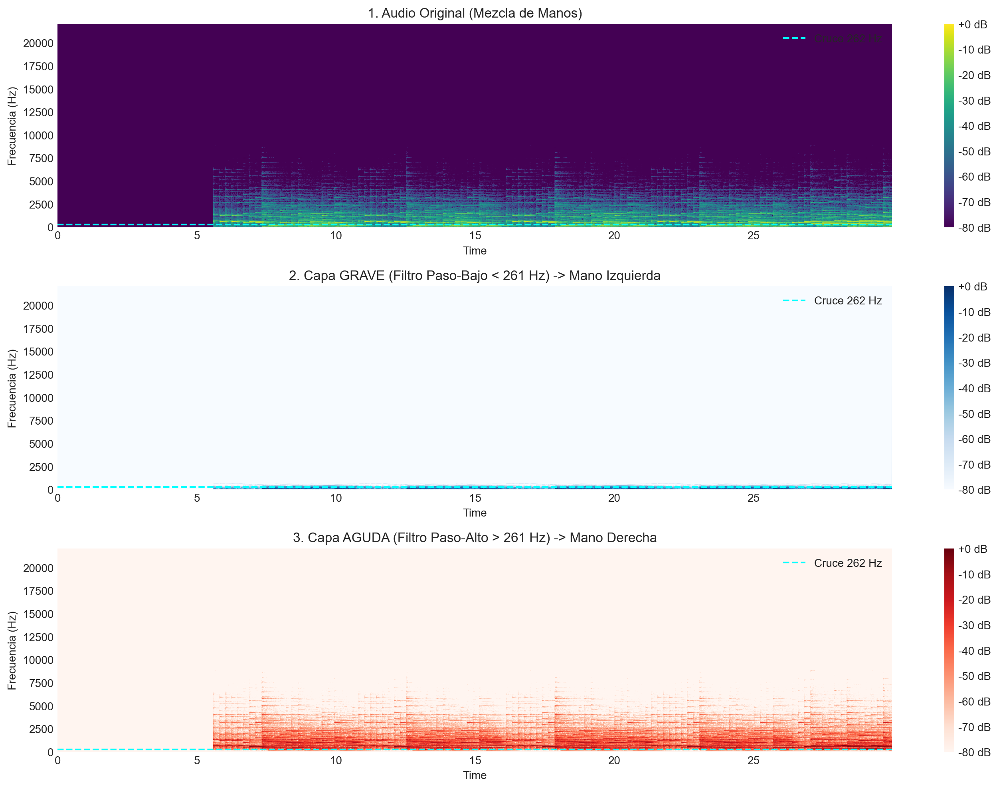


 🎧 EVALUACIÓN AUDITIVA (Usa audífonos)
🔊 1. Audio ORIGINAL (Piano completo):



🔊 2. Capa GRAVE (Mano Izquierda / Bajos):
   (Escucha: ¿Se aisló el bajo? ¿Se filtra algo de melodía?)



🔊 3. Capa AGUDA (Mano Derecha / Melodía):
   (Escucha: ¿La melodía está limpia? ¿Se coló algo de bajo?)



 📝 CONCLUSIÓN PARA LA ARQUITECTURA HARMONIC SCORE

    Si al escuchar notaste que:
    a) La separación es 'sucia' (se escuchan armónicos del otro lado):
       -> La separación a nivel de AUDIO (filtros) NO es suficiente para 
          transcripción de alta fidelidad.
       
    b) La solución real:
       -> Debemos transcribir el stem completo con YourMT3+ y hacer la 
          separación a nivel de NOTAS (MIDI) en el post-procesamiento 
          (score_stage.py), usando el umbral de pitch (ej. MIDI 60).
          
    Este experimento de audio sirve para justificar en la tesis por qué 
    elegimos la separación heurística por rango MIDI en lugar de 
    procesamiento de señales en bruto.
    


In [10]:
# ==============================================================================
# HARMONIC SCORE: Prueba de Separación Auditiva de Manos (Piano Polifónico)
# Objetivo: Escuchar y visualizar la separación de un instrumento polifónico 
# en dos capas (Graves/Mano Izquierda y Agudos/Mano Derecha) usando filtros 
# de cruce de frecuencia (Crossover).
# ==============================================================================

import os
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
import IPython.display as ipd
from scipy.signal import butter, sosfiltfilt
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-darkgrid')

# ==============================================================================
# 1. CONFIGURACIÓN Y CARGA DE AUDIO
# ==============================================================================

# TODO: Reemplaza con la ruta de tu stem de piano (ej. de Demucs) o audio de piano solo
RUTA_AUDIO = r"C:\Users\artuk\OneDrive\Documentos\tarea\ESCOM\TITULACION\TT\harmonic-score-app\ml-service\storage\tests\v2\Für Elise - Ludwig van Beethoven.mp3" 

# Frecuencia de cruce (Crossover). El Do central (C4) es ~261.63 Hz
FREC_CRUCE = 261.63 

print(f"📂 Cargando audio desde: {RUTA_AUDIO}")
if not os.path.exists(RUTA_AUDIO):
    print("❌ Error: El archivo no existe. Verifica la ruta.")
else:
    # Cargar audio (primeros 30s para prueba rápida)
    y, sr = librosa.load(RUTA_AUDIO, sr=44100, mono=True, duration=30)
    print(f"✅ Audio cargado. Duración: {len(y)/sr:.2f}s | SR: {sr} Hz")

    # ==============================================================================
    # 2. APLICACIÓN DE FILTROS CROSSOVER (Butterworth)
    # ==============================================================================
    print(f"\n🎛️ Aplicando filtros crossover en {FREC_CRUCE} Hz (Do4)...")
    
    nyquist = 0.5 * sr
    normal_cutoff = FREC_CRUCE / nyquist
    
    # Diseño de filtros Butterworth de orden 4 (sos para estabilidad numérica)
    sos_low = butter(4, normal_cutoff, btype='low', output='sos')
    sos_high = butter(4, normal_cutoff, btype='high', output='sos')
    
    # Filtrado de fase cero (evita distorsión de fase en el audio)
    print("Procesando filtros...")
    y_low = sosfiltfilt(sos_low, y)   # Mano Izquierda (Graves)
    y_high = sosfiltfilt(sos_high, y) # Mano Derecha (Agudos)
    
    # Normalizar para que el volumen sea comparable al original
    y_low = librosa.util.normalize(y_low) * 0.9
    y_high = librosa.util.normalize(y_high) * 0.9
    
    print("✅ Filtrado completado.")

    # ==============================================================================
    # 3. VISUALIZACIÓN ESPECTRAL (Espectrogramas)
    # ==============================================================================
    print("\n📊 Generando espectrogramas comparativos...")
    
    fig, axes = plt.subplots(3, 1, figsize=(14, 10))
    
    def plot_spec(ax, audio, title, cmap='magma'):
        S = np.abs(librosa.stft(audio, n_fft=2048, hop_length=512))
        # Mostrar hasta 4000 Hz para ver bien el detalle del piano
        img = librosa.display.specshow(
            librosa.amplitude_to_db(S, ref=np.max),
            sr=sr, x_axis='time', y_axis='linear', 
            ax=ax, cmap=cmap, fmax=4000
        )
        ax.set_title(title)
        ax.set_ylabel('Frecuencia (Hz)')
        fig.colorbar(img, ax=ax, format="%+2.0f dB")
        # Marcar la frecuencia de cruce
        ax.axhline(y=FREC_CRUCE, color='cyan', linestyle='--', linewidth=1.5, label=f'Cruce {FREC_CRUCE:.0f} Hz')
        ax.legend(loc='upper right')

    plot_spec(axes[0], y, "1. Audio Original (Mezcla de Manos)", 'viridis')
    plot_spec(axes[1], y_low, "2. Capa GRAVE (Filtro Paso-Bajo < 261 Hz) -> Mano Izquierda", 'Blues')
    plot_spec(axes[2], y_high, "3. Capa AGUDA (Filtro Paso-Alto > 261 Hz) -> Mano Derecha", 'Reds')

    plt.tight_layout()
    plt.show()

    # ==============================================================================
    # 4. EVALUACIÓN AUDITIVA (A/B Testing)
    # ==============================================================================
    print("\n" + "="*70)
    print(" 🎧 EVALUACIÓN AUDITIVA (Usa audífonos)")
    print("="*70)
    
    print("🔊 1. Audio ORIGINAL (Piano completo):")
    ipd.display(ipd.Audio(y, rate=sr))
    
    print("\n🔊 2. Capa GRAVE (Mano Izquierda / Bajos):")
    print("   (Escucha: ¿Se aisló el bajo? ¿Se filtra algo de melodía?)")
    ipd.display(ipd.Audio(y_low, rate=sr))
    
    print("\n🔊 3. Capa AGUDA (Mano Derecha / Melodía):")
    print("   (Escucha: ¿La melodía está limpia? ¿Se coló algo de bajo?)")
    ipd.display(ipd.Audio(y_high, rate=sr))

    # ==============================================================================
    # 5. CONCLUSIÓN PARA EL PIPELINE
    # ==============================================================================
    print("\n" + "="*70)
    print(" 📝 CONCLUSIÓN PARA LA ARQUITECTURA HARMONIC SCORE")
    print("="*70)
    print("""
    Si al escuchar notaste que:
    a) La separación es 'sucia' (se escuchan armónicos del otro lado):
       -> La separación a nivel de AUDIO (filtros) NO es suficiente para 
          transcripción de alta fidelidad.
       
    b) La solución real:
       -> Debemos transcribir el stem completo con YourMT3+ y hacer la 
          separación a nivel de NOTAS (MIDI) en el post-procesamiento 
          (score_stage.py), usando el umbral de pitch (ej. MIDI 60).
          
    Este experimento de audio sirve para justificar en la tesis por qué 
    elegimos la separación heurística por rango MIDI en lugar de 
    procesamiento de señales en bruto.
    """)